# Самостоятельная работа. Механические свойства низколегированных сталей

подключаем библиотеки

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  

In [3]:
from scipy import stats 


In [4]:
pd.set_option('display.float_format', '{:.4g}'.format)

In [5]:
sns.set_theme(style='whitegrid')

## Задание 1. Знакомимся с таблицами

In [6]:
состав = pd.read_csv('Занятие_7/2_самостоятельная_работа/состав_сталей.csv')
испытания = pd.read_csv('Занятие_7/2_самостоятельная_работа/испытания_сталей.csv')

In [7]:
состав

,марка,C,Si,Mn,P,S,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta
0,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0
1,MBC,0.09,0.37,0.49,0.006,0.005,0.055,0.98,0.57,0.07,0,0.005,0.008,0,0
2,MBD,0.1,0.28,0.49,0.008,0.009,0.028,0.9,0.56,0.08,0,0.006,0.009,0,0
3,MBE,0.12,0.43,0.48,0.014,0.008,0.051,0.96,0.56,0.08,0,0.006,0.008,0,0
4,MBF,0.12,0.28,0.44,0.018,0.008,0.03,0.99,0.54,0.08,0,0.007,0.01,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,CbX,0.17,0.49,1.26,0.013,0.01,0.01,0.02,0.09,0.02,0.04,0.045,0.0025,0.429,0
91,CbY,0.13,0.42,1.28,0.014,0.012,0.21,0.22,0.05,0.04,0.03,0.037,0.0072,0.424,0
92,CbZ,0.16,0.41,1.48,0.014,0.01,0.02,0.02,0.01,0.03,0.08,0.033,0.0079,0.436,0
93,CCA,0.23,0.23,1.23,0.027,0.012,0.03,0.04,0.017,0.01,0.009,0.003,0.0111,0,0.0017


In [8]:
испытания

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение
0,MBB,27,342,490,30,71
1,MBB,100,338,454,27,72
2,MBB,200,337,465,23,69
3,MBB,300,346,495,21,70
4,MBB,400,316,489,26,79
...,...,...,...,...,...,...
910,CCB,350,268,632,28,65
911,CCB,400,244,575,28,68
912,CCB,450,224,500,29,72
913,CCB,500,209,428,30,78


количество строк и столбцов каждой таблицы

In [9]:
состав.shape

(95, 15)

In [10]:
состав.head()

,марка,C,Si,Mn,P,S,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta
0,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0
1,MBC,0.09,0.37,0.49,0.006,0.005,0.055,0.98,0.57,0.07,0,0.005,0.008,0,0
2,MBD,0.1,0.28,0.49,0.008,0.009,0.028,0.9,0.56,0.08,0,0.006,0.009,0,0
3,MBE,0.12,0.43,0.48,0.014,0.008,0.051,0.96,0.56,0.08,0,0.006,0.008,0,0
4,MBF,0.12,0.28,0.44,0.018,0.008,0.03,0.99,0.54,0.08,0,0.007,0.01,0,0


In [11]:
состав.info()

<class 'pandas.DataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   марка   95 non-null     str    
 1   C       95 non-null     float64
 2   Si      95 non-null     float64
 3   Mn      95 non-null     float64
 4   P       95 non-null     float64
 5   S       95 non-null     float64
 6   Ni      95 non-null     float64
 7   Cr      95 non-null     float64
 8   Mo      95 non-null     float64
 9   Cu      95 non-null     float64
 10  V       95 non-null     float64
 11  Al      95 non-null     float64
 12  N       95 non-null     float64
 13  Ceq     95 non-null     float64
 14  Nb_Ta   95 non-null     float64
dtypes: float64(14), str(1)
memory usage: 11.3 KB


In [12]:
испытания.shape

(915, 6)

In [13]:
испытания.head()

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение
0,MBB,27,342,490,30,71
1,MBB,100,338,454,27,72
2,MBB,200,337,465,23,69
3,MBB,300,346,495,21,70
4,MBB,400,316,489,26,79


In [14]:
испытания.info()

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   марка             915 non-null    str  
 1   температура       915 non-null    int64
 2   предел_текучести  915 non-null    int64
 3   предел_прочности  915 non-null    int64
 4   удлинение         915 non-null    int64
 5   сужение           915 non-null    int64
dtypes: int64(5), str(1)
memory usage: 43.0 KB


## Задание 2. Проверяем ключ и склеиваем таблицы

In [15]:
состав['марка'].nunique()

95

In [16]:
испытания['марка'].nunique()

95

In [17]:
состав['марка'].is_unique

True

In [18]:
испытания['марка'].is_unique

False

в составе каждая марка один раз, а в испытаниях одна марка имеет несколько испытания, поэтому получим связь - многие к одному

In [19]:
set(испытания['марка']) - set(состав['марка'])

set()

все марки испытаний есть в таблице состава

In [20]:
результат = испытания.merge(состав, on="марка", how="left", validate="many_to_one", indicator=True)
результат

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge
0,MBB,27,342,490,30,71,0.12,0.36,0.52,0.009,...,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0,both
1,MBB,100,338,454,27,72,0.12,0.36,0.52,0.009,...,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0,both
2,MBB,200,337,465,23,69,0.12,0.36,0.52,0.009,...,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0,both
3,MBB,300,346,495,21,70,0.12,0.36,0.52,0.009,...,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0,both
4,MBB,400,316,489,26,79,0.12,0.36,0.52,0.009,...,0.089,0.97,0.61,0.04,0,0.003,0.0066,0,0,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
910,CCB,350,268,632,28,65,0.22,0.22,1.24,0.021,...,0.03,0.05,0.017,0.01,0.005,0.005,0.0116,0,0.0017,both
911,CCB,400,244,575,28,68,0.22,0.22,1.24,0.021,...,0.03,0.05,0.017,0.01,0.005,0.005,0.0116,0,0.0017,both
912,CCB,450,224,500,29,72,0.22,0.22,1.24,0.021,...,0.03,0.05,0.017,0.01,0.005,0.005,0.0116,0,0.0017,both
913,CCB,500,209,428,30,78,0.22,0.22,1.24,0.021,...,0.03,0.05,0.017,0.01,0.005,0.005,0.0116,0,0.0017,both


how выбираем left, потому что таблица испытаний основная, и нам нужны все испытания

In [21]:
len(результат)

915

In [22]:
len(испытания)

915

в итоге получилось 915 строк, это значение совпадает с числом испытаний

In [23]:
результат['_merge'].value_counts()

_merge
both          915
left_only       0
right_only      0
Name: count, dtype: int64

## Задание 3. Пропуски, в том числе скрытые

In [24]:
результат.isna()

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
910,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
911,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
912,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
913,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [25]:
результат.isna().sum()

марка               0
температура         0
предел_текучести    0
предел_прочности    0
удлинение           0
сужение             0
C                   0
Si                  0
Mn                  0
P                   0
S                   0
Ni                  0
Cr                  0
Mo                  0
Cu                  0
V                   0
Al                  0
N                   0
Ceq                 0
Nb_Ta               0
_merge              0
dtype: int64

пустых клеток нет

In [26]:
(состав == 0).sum()

марка     0
C         0
Si        0
Mn        0
P         0
S         0
Ni       16
Cr        6
Mo        0
Cu        3
V        57
Al        0
N         0
Ceq      74
Nb_Ta    93
dtype: int64

много нулей в столбцах V, Ceq, Nb_Ta

In [27]:
состав['Ceq'].mean()

np.float64(0.09052631578947368)

комьютер посчитал скрытые пропуски настоящими нулями, заменим их на NaN:

In [28]:
состав['Ceq'] = состав['Ceq'].replace(0, np.nan)

In [29]:
состав['Ceq'].mean()

np.float64(0.4095238095238095)

## Задание 4. Какие группы есть в данных

посчитаем сколько испытаний проведено при каждой температуре

In [30]:
результат['температура'].value_counts().sort_index()

температура
27     95
100    95
150     2
200    95
250     2
300    95
350    45
400    95
450    95
500    95
550    95
600    76
650    30
Name: count, dtype: int64

при температуре 150, 250, 350, 650 очень мало испытаний, а при 27, 100, 200, 300, 400, 450, 500, 550 много испытаний

2 испытания слишком мало, результаты могут оказаться случайными и плохо отражать реальные свойства стали 

In [31]:
результат.groupby('температура')['предел_прочности'].agg(['count', 'median'])

,count,median
температура,,
27,95,530
100,95,510
150,2,650.5
200,95,566
250,2,703
300,95,574
350,45,572
400,95,517
450,95,475


при повышении температуры, прочность снижается

In [32]:
ошибки = результат[результат['предел_текучести'] > результат['предел_прочности']]

ошибки

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge
680,VbN,550,408,162,18,80,0.15,0.52,0.78,0.01,...,0.12,1.17,0.98,0.08,0.23,0.003,0.0106,0,0,both


## Задание 5. Логическая проверка данных

найдем испытания где предел текучести больше предела прочности 

In [33]:
len(ошибки)

1

In [56]:
результат.describe()

,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,S,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta
count,915,915,915,915,915,915,915,915,915,915,915,915,915,915,915,915,915,915,915
mean,351.6,328.2,496.2,26.79,70.21,0.1749,0.3109,0.813,0.01454,0.0106,0.143,0.4279,0.4429,0.07915,0.06019,0.01243,0.007652,0.09399,4.087e-05
std,189.7,131.7,239.7,8.807,12.39,0.05967,0.08687,0.3428,0.005244,0.004024,0.1727,0.4576,0.3944,0.05848,0.0964,0.01307,0.002321,0.1725,0.0002606
min,27,27,162,10,18,0.09,0.18,0.42,0.006,0.003,0,0,0.005,0,0,0.002,0.0025,0,0
25%,200,220,413,20,62,0.13,0.24,0.5,0.01,0.008,0.023,0.04,0.05,0.04,0,0.004,0.0062,0,0
50%,400,290,479,26,71,0.16,0.3,0.68,0.014,0.01,0.05,0.11,0.5,0.07,0,0.006,0.0076,0,0
75%,500,432.5,575,31,80,0.2,0.37,1.21,0.018,0.012,0.21,1,0.56,0.11,0.07,0.016,0.009,0,0
max,650,690,6661,78,94,0.34,0.52,1.48,0.03,0.022,0.6,1.31,1.35,0.25,0.3,0.05,0.015,0.437,0.0017


In [57]:
результат[['предел_текучести','предел_прочности']].describe()

,предел_текучести,предел_прочности
count,915,915
mean,328.2,496.2
std,131.7,239.7
min,27,162
25%,220,413
50%,290,479
75%,432.5,575
max,690,6661


162 и 6661 подозрительно выбиваются из ряда значений. просмотрим минимальные и максимальные значения двух столбцов

In [58]:
результат.sort_values('предел_прочности').head(10)

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
680,VbN,550,408,162,18,80,0.15,0.52,0.78,0.01,...,1.17,0.98,0.08,0.23,0.003,0.0106,0,0,both,False
79,MBJ,650,114,199,54,94,0.1,0.35,0.44,0.02,...,1.01,0.51,0.08,0,0.012,0.0082,0,0,both,False
19,MBC,650,132,205,67,92,0.09,0.37,0.49,0.006,...,0.98,0.57,0.07,0,0.005,0.008,0,0,both,False
181,CAM,550,137,209,57,90,0.2,0.31,0.5,0.022,...,0.017,0.006,0.09,0,0.004,0.0037,0,0,both,False
59,MBG,650,122,211,51,92,0.12,0.37,0.45,0.018,...,1,0.5,0.06,0,0.009,0.0088,0,0,both,False
89,MBL,650,137,213,78,90,0.09,0.32,0.48,0.02,...,1.05,0.52,0.04,0,0.009,0.0089,0,0,both,False
69,MBH,650,124,214,54,93,0.12,0.36,0.45,0.018,...,1,0.53,0.05,0,0.007,0.008,0,0,both,False
99,MBM,650,136,217,52,90,0.1,0.31,0.51,0.022,...,1.03,0.53,0.04,0,0.009,0.0076,0,0,both,False
190,CAN,550,125,219,58,87,0.23,0.32,0.53,0.023,...,0.022,0.005,0.07,0,0.005,0.0051,0,0,both,False
109,MBN,650,150,220,46,90,0.1,0.3,0.49,0.02,...,1.04,0.5,0.04,0,0.009,0.0089,0,0,both,False


In [59]:
результат.sort_values('предел_прочности').tail(10)

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
643,VbH,27,650,790,16,49,0.18,0.37,0.61,0.019,...,1.09,1.12,0.07,0.28,0.016,0.0064,0,0,both,False
441,Vaj,27,640,800,18,62,0.29,0.21,0.66,0.01,...,1.07,1.29,0.06,0.23,0.005,0.0097,0,0,both,False
381,VaB,27,665,810,18,63,0.28,0.18,0.75,0.012,...,1,1.25,0.14,0.27,0.002,0.009,0,0,both,False
451,VaR,27,655,810,18,62,0.3,0.27,0.7,0.012,...,1.1,1.35,0.11,0.27,0.003,0.0082,0,0,both,False
371,VaA,27,655,810,17,61,0.28,0.2,0.72,0.015,...,1.02,1.12,0.2,0.27,0.002,0.0075,0,0,both,False
401,VaD,27,645,810,19,60,0.3,0.28,0.72,0.014,...,0.93,1.22,0.16,0.21,0.002,0.0093,0,0,both,False
431,VaH,27,660,820,17,59,0.29,0.26,0.77,0.009,...,1.12,1.2,0.08,0.23,0.004,0.0095,0,0,both,False
391,VaC,27,690,830,17,59,0.29,0.2,0.75,0.01,...,1,1.25,0.14,0.26,0.002,0.0075,0,0,both,False
421,VaG,27,685,830,17,62,0.29,0.26,0.76,0.009,...,1.12,1.18,0.07,0.23,0.003,0.0103,0,0,both,False
626,VbF,300,519,6661,11,28,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,True


In [60]:
результат.sort_values('предел_текучести').head(10)

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
891,CbZ,550,27,375,38,81,0.16,0.41,1.48,0.014,...,0.02,0.01,0.03,0.08,0.033,0.0079,0.436,0,both,False
79,MBJ,650,114,199,54,94,0.1,0.35,0.44,0.02,...,1.01,0.51,0.08,0,0.012,0.0082,0,0,both,False
163,CAJ,550,114,231,44,76,0.2,0.2,0.47,0.007,...,0.056,0.01,0.07,0,0.005,0.011,0,0,both,False
59,MBG,650,122,211,51,92,0.12,0.37,0.45,0.018,...,1,0.5,0.06,0,0.009,0.0088,0,0,both,False
69,MBH,650,124,214,54,93,0.12,0.36,0.45,0.018,...,1,0.53,0.05,0,0.007,0.008,0,0,both,False
190,CAN,550,125,219,58,87,0.23,0.32,0.53,0.023,...,0.022,0.005,0.07,0,0.005,0.0051,0,0,both,False
127,CAB,550,127,229,44,88,0.2,0.28,0.6,0.018,...,0.045,0.01,0.05,0,0.005,0.0066,0,0,both,False
118,CAA,550,131,234,61,90,0.2,0.31,0.59,0.018,...,0.046,0.011,0.05,0,0.006,0.0056,0,0,both,False
19,MBC,650,132,205,67,92,0.09,0.37,0.49,0.006,...,0.98,0.57,0.07,0,0.005,0.008,0,0,both,False
136,CAC,550,135,237,60,89,0.2,0.29,0.55,0.021,...,0.054,0.012,0.05,0,0.004,0.0058,0,0,both,False


In [61]:
результат.sort_values('предел_текучести').tail(10)

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
401,VaD,27,645,810,19,60,0.3,0.28,0.72,0.014,...,0.93,1.22,0.16,0.21,0.002,0.0093,0,0,both,False
643,VbH,27,650,790,16,49,0.18,0.37,0.61,0.019,...,1.09,1.12,0.07,0.28,0.016,0.0064,0,0,both,False
371,VaA,27,655,810,17,61,0.28,0.2,0.72,0.015,...,1.02,1.12,0.2,0.27,0.002,0.0075,0,0,both,False
451,VaR,27,655,810,18,62,0.3,0.27,0.7,0.012,...,1.1,1.35,0.11,0.27,0.003,0.0082,0,0,both,False
431,VaH,27,660,820,17,59,0.29,0.26,0.77,0.009,...,1.12,1.2,0.08,0.23,0.004,0.0095,0,0,both,False
392,VaC,100,662,786,16,58,0.29,0.2,0.75,0.01,...,1,1.25,0.14,0.26,0.002,0.0075,0,0,both,False
381,VaB,27,665,810,18,63,0.28,0.18,0.75,0.012,...,1,1.25,0.14,0.27,0.002,0.009,0,0,both,False
773,CbL,27,666,676,23,70,0.12,0.33,1.37,0.016,...,0.03,0.01,0.03,0.08,0.042,0.007,0.381,0,both,False
421,VaG,27,685,830,17,62,0.29,0.26,0.76,0.009,...,1.12,1.18,0.07,0.23,0.003,0.0103,0,0,both,False
391,VaC,27,690,830,17,59,0.29,0.2,0.75,0.01,...,1,1.25,0.14,0.26,0.002,0.0075,0,0,both,False


найдем строку с которой началась погрешность значений

In [62]:
результат.sort_values('предел_прочности', ascending=False).head()

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
626,VbF,300,519,6661,11,28,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,True
391,VaC,27,690,830,17,59,0.29,0.2,0.75,0.01,...,1,1.25,0.14,0.26,0.002,0.0075,0,0,both,False
421,VaG,27,685,830,17,62,0.29,0.26,0.76,0.009,...,1.12,1.18,0.07,0.23,0.003,0.0103,0,0,both,False
431,VaH,27,660,820,17,59,0.29,0.26,0.77,0.009,...,1.12,1.2,0.08,0.23,0.004,0.0095,0,0,both,False
401,VaD,27,645,810,19,60,0.3,0.28,0.72,0.014,...,0.93,1.22,0.16,0.21,0.002,0.0093,0,0,both,False


просмотрим все испытания марки VbF при разных температурах

In [63]:
результат[результат['марка'] == 'VbF'].sort_values('температура')

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
623,VbF,27,545,690,18,46,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
624,VbF,100,584,716,13,47,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
625,VbF,200,572,714,14,18,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
626,VbF,300,519,6661,11,28,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,True
627,VbF,400,482,629,16,50,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
628,VbF,450,471,592,15,44,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
629,VbF,500,444,546,17,62,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
630,VbF,550,473,535,15,68,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
631,VbF,600,359,416,19,77,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False
632,VbF,650,278,343,23,82,0.18,0.37,0.66,0.018,...,1.07,1.03,0.12,0.3,0.02,0.0081,0,0,both,False


при температуре 300 предел прочности составил 6661, это подозрительно большое значение. если посмотреть на соседние числа (714 и 629) можно предположить что была добавлена лишняя цифра и реальное значение около 661 либо 666.

запись следует проверить по исходным данным. если данных нет, то ее лучше удалить или пометить как ошибочную, ведь она сильно искажает результаты анализа

создадим флаг

In [78]:
ошибки = результат[результат['предел_текучести'] > результат['предел_прочности']]

In [95]:
ошибки

,марка,температура,предел_текучести,предел_прочности,удлинение,сужение,C,Si,Mn,P,...,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,_merge,ошибка
680,VbN,550,408,162,18,80,0.15,0.52,0.78,0.01,...,1.17,0.98,0.08,0.23,0.003,0.0106,0,0,both,False


In [96]:
результат['ошибка'] = False

результат.loc[(результат['марка'] == 'VbF') & (результат['температура'] == 300),
'ошибка'] = True

# вторая ошибка: предел текучести больше предела прочности
результат.loc[(результат['марка'] == 'VbN') & (результат['температура'] == 550),
'ошибка'] = True

In [97]:
результат['ошибка'].sum()

np.int64(2)

вышло 2 неверные строки

In [98]:
чистые = результат[~результат['ошибка']].copy()

было строк

In [99]:
len(результат) # type: ignore

915

стало строк

In [100]:
len(чистые) # type: ignore

913

мы исключили 2 строки

## Задание 6. Описательная статистика при комнатной температуре

отберем испытания при 27 градусах

In [101]:
комнатная = чистые[чистые['температура'] == 27] # type: ignore

посчитаем describe для нужных столбцов

In [102]:
комнатная[['предел_текучести','предел_прочности','удлинение','сужение']].describe() # type: ignore

,предел_текучести,предел_прочности,удлинение,сужение
count,95,95,95,95
mean,413.3,572.3,26.64,66.63
std,139.8,119,6.037,7.403
min,239,430,15,36
25%,287.5,470,22,63
50%,380,530,27,66
75%,531.5,666,32,71
max,690,830,36,79


посчитаем межквартильный размах и коэффицент вариации для предела прочности

In [103]:
q1 = комнатная['предел_прочности'].quantile(0.25) # type: ignore
q3 = комнатная['предел_прочности'].quantile(0.75) # type: ignore

iqr = q3 - q1 # type: ignore

print(iqr) # type: ignore

196.0


In [104]:
cv_прочность = (комнатная['предел_прочности'].std() / комнатная['предел_прочности'].mean() # type: ignore
 * 100)

cv_прочность # type: ignore

np.float64(20.790450947212463)

In [105]:
cols = ['предел_текучести','предел_прочности','удлинение','сужение']

for col in cols:
    cv = комнатная[col].std() / комнатная[col].mean() * 100 # type: ignore
    print(col, round(cv, 2)) # type: ignore

предел_текучести 33.82
предел_прочности 20.79
удлинение 22.66
сужение 11.11


сильнее всего меняется признак предела текучести, меньше всего у признака сужения

## Задание 7. Типы стали как группы. Проверка нормальности

In [106]:
условия = [
    (чистые['Cr'] > 0.3) & (чистые['Mo'] > 0.1),
    (чистые['Mo'] > 0.1),
]
названия = ['хромомолибденовая', 'молибденовая']
чистые['тип'] = np.select(условия, названия, default='углеродисто-марганцевая')

комнатная = чистые[чистые['температура'] == 27].copy()
комнатная['тип'].value_counts()

тип
хромомолибденовая          38
углеродисто-марганцевая    35
молибденовая               22
Name: count, dtype: int64

проверим нормальность по всем маркам вместе, сделая гистограмму

<Axes: xlabel='предел_прочности', ylabel='Count'>

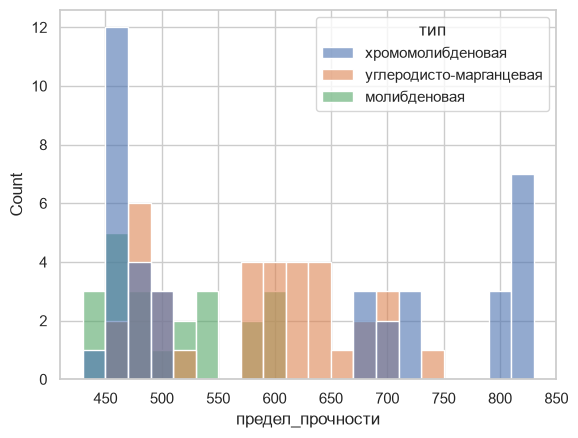

In [107]:
sns.histplot(data=комнатная,x='предел_прочности',hue='тип',bins=20,alpha=0.6)

на гистограмме хромомолибденовых сталей видно несколько гор. это может значить, что марки одного типа могли пройти разную термообработку

In [108]:
stats.shapiro( # type: ignore
    комнатная['предел_прочности']).pvalue # type: ignore

np.float64(4.750701810374907e-07)

данные по всем маркам вместе не нормальны, поскольку мы обьеденили разные типы стали с различными свойствами. проверим марки по типам


In [109]:
for t in комнатная['тип'].unique():

    x = комнатная.loc[
        комнатная['тип'] == t,
        'предел_прочности'
    ]

    print(t, stats.shapiro(x).pvalue) # type: ignore

хромомолибденовая 8.10135937264198e-06
углеродисто-марганцевая 0.02075521954891858
молибденовая 0.016671177732415672


Построим также графики для каждого типа стали.

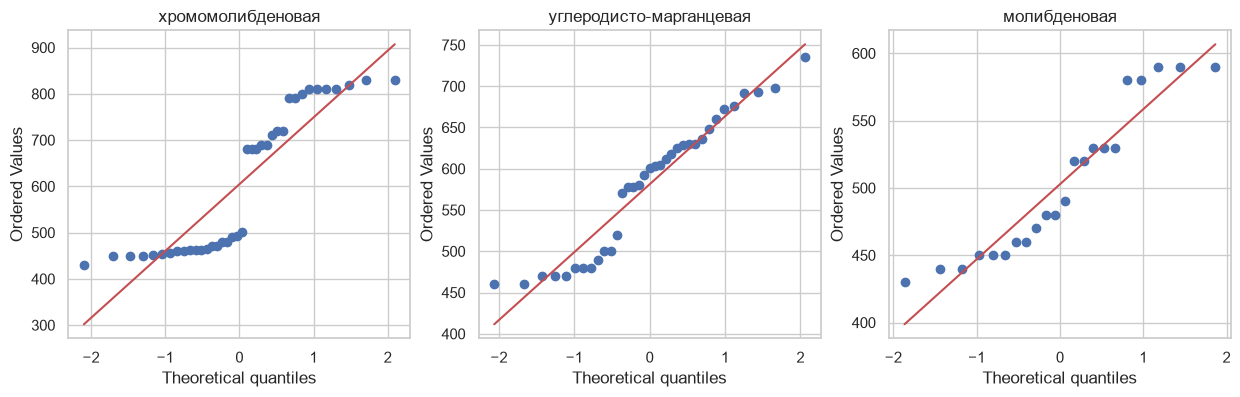

In [110]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, комнатная['тип'].unique()):
    x = комнатная.loc[комнатная['тип'] == t, 'предел_прочности']
    stats.probplot(x, dist='norm', plot=ax)
    ax.set_title(t)
plt.show()

даже после разделения на типы все значения тоже оказались ненормальны

предел прочности каждого типа запишем в виде медианы [Q1; Q3], а не в виде среднее ± стандартное отклонение, поскольку данные не нормальны и внутри типов присутствует неоднородность 

## Задание 8. Выбросы при высокой температуре